# Imports

In [112]:
import numpy as np
import matplotlib.pyplot as plt
#matplotlib inline
import keras
from keras import Input
from keras.models import Sequential
from keras.layers import Dense, Dropout
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Set seed for np for consistency in our neural network.
np.random.seed(0)



# Get Data

In [113]:
from keras.datasets import mnist

# Load the MNIST data set into two parts our training set and our testing set.
# x is the input / training example, y is the output / answer (y = f(x), f is our model)
(x_train, y_train), (x_test, y_test) = mnist.load_data()

In [114]:
# print the data sets dimensions (n inputs, dim1, dim2, ...)
print(x_train.shape, y_train.shape)
print(x_test.shape, y_test.shape)

(60000, 28, 28) (60000,)
(10000, 28, 28) (10000,)


# Visualize Examples

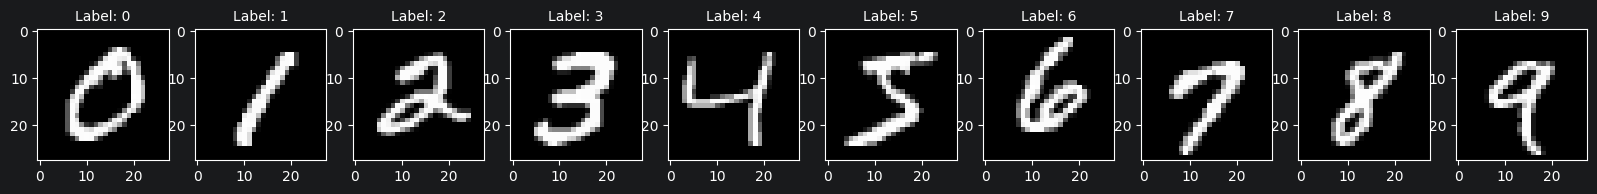

In [115]:
# defines how many plots we will have
num_classes = 10

# creates a figure (20 by 20) and fits [1 (num rows) x num_classes (num columns)] matrix on it
f, ax = plt.subplots(1, num_classes, figsize = (20, 5))


for i in range(0, num_classes):

    # x_train[y_train == i] filters out all training images that aren't the number i
    # the first elem in this filtered array is used as the sample
    sample = x_train[y_train == i][0]

    # makes every image grayscale (lowest pixel value = black, highest pixel value = white)
    ax[i].imshow(sample, cmap = 'gray')
    ax[i].set_title(f"Label: {i}", fontsize = 10)


# Data Preparation

In [116]:
# transforms answer keys from just numbers to vectors (ex. 5 -> [0,0,0,0,0,1,0,0,0,0]) to
# resemble the output from the model
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)


In [117]:
WHITE_PIXEL = 255

# normalizes the data so for each vector the values go from [0, 255] -> [0, 1] range
# white pixels have a value of 1, all else have a value nearly 0, black pixels basically have a value of 0
x_train = x_train / WHITE_PIXEL
x_test = x_test / WHITE_PIXEL

In [118]:
# flattens each matrix in our data set from [28, 28] to a vector of size 784
x_train = x_train.reshape(x_train.shape[0], -1)
x_test = x_test.reshape(x_test.shape[0], -1)

# Create Model - Fully Connected Neural Network

In [119]:

# Sequential model gives the typical input -> hidden -> output structure
model = Sequential()

# input layer for our model
model.add(Input(shape=(784,)))


# hidden layers for our model, Dense means each neuron in the layer is connected to every neuron in the
# previous layer
model.add(Dense(units=128, activation = 'relu'))
model.add(Dense(units=128, activation = 'relu'))

# dropout layer randomly sets 25% of our neurons to 0, this helps prevent the model from depending on
# certain neurons or inputs
model.add(Dropout(0.25))

# output layer for our model
model.add(Dense(units=10, activation = 'softmax'))

# our model will use cross entropy for the cost function, adam to determine the step size each weight
# should take, and will report the accuracy of the model back to us as a metric
model.compile(loss = 'categorical_crossentropy', optimizer = 'adam', metrics = ['accuracy'])

# provides us a table representation of our model's layers
model.summary()



Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_36 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_37 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_38 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 118,282 (462.04 KB)

 Trainable params: 118,282 (462.04 KB)

 Non-trainable params: 0 (0.00 B)

# Train

In [120]:
# amount of images we run our model through before we update weights
batch_size = 512

# amount of times we run our model through the complete x_train dataset.
epochs = 10
model.fit(x = x_train, y = y_train, batch_size = batch_size, epochs = epochs)

Epoch 1/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6841 - loss: 1.0515   
Epoch 2/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9309 - loss: 0.2432 
Epoch 3/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9494 - loss: 0.1735 
Epoch 4/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9607 - loss: 0.1345 
Epoch 5/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9669 - loss: 0.1141 
Epoch 6/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9726 - loss: 0.0920 
Epoch 7/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9754 - loss: 0.0816 
Epoch 8/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9781 - loss: 0.0718 
Epoch 9/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9814 - loss: 0.0607 
Epoch 10/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9841 - loss: 0.0520 


# Evaluate our Model

In [121]:
# get and print out the loss and accuracy of our model
# loss tells us how strong our model is
# accuracy tells us how right our model is
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"test loss: {test_loss}, test accuracy: {test_acc}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 455us/step - accuracy: 0.9727 - loss: 0.0840
test loss: 0.07402610778808594, test accuracy: 0.9764000177383423


In [122]:
# gives us a matrix, where each vector represents the models output layer (probability distribution)
# for that input
y_pred = model.predict(x_test)

# gives us a vector, where we take each vector in y_pred and return the index of the higher probability
# (giving us the number that the model was most confident the image represented)
# axis of 0 tells the model to look at each column and return the max, 1 tells to look at each row
y_pred_classes = np.argmax(y_pred, axis=1)

print(y_pred)
print(y_pred_classes)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 360us/step
[[4.35413995e-06 1.10115889e-05 4.00634744e-04 ... 9.98509347e-01
  9.35250227e-06 1.19601164e-05]
 [5.51093997e-08 1.21133220e-04 9.99873996e-01 ... 1.38987144e-09
  1.14691915e-07 8.32864958e-11]
 [2.51087586e-05 9.96207654e-01 3.26941517e-04 ... 2.21840711e-03
  9.45259701e-04 2.28392746e-05]
 ...
 [1.71633818e-10 6.89202295e-09 2.07708362e-09 ... 3.36284506e-06
  1.83492119e-07 5.12948736e-06]
 [1.77804456e-08 2.12041429e-09 1.66143332e-09 ... 4.82518969e-10
  3.57563622e-05 6.11480289e-09]
 [1.41975690e-07 1.55631993e-10 5.80285331e-08 ... 2.81460445e-12
  1.37900705e-10 2.62838952e-11]]
[7 2 1 ... 4 5 6]


Predicted: 6, Actual: 6


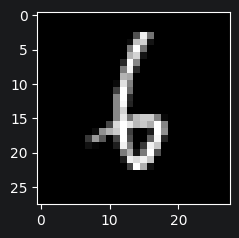

In [123]:
# get a random test image from x_test
random_test_index = np.random.choice(len(x_test))
random_test_image = x_test[random_test_index]

# get the actual number that the random test image was representing
y_true_number = np.argmax(y_test, axis=1)[random_test_index]

# get the predicted number that the random test image was representing
y_pred_number = np.argmax(y_pred, axis=1)[random_test_index]

# display the predicted number and the true number
print(f"Predicted: {y_pred_number}, Actual: {y_true_number}")

# display the random test image reshaped back to its 28 by 28 size so we can
# properly visualize the image and shrink the fig size down so the image is not so big
plt.figure(figsize = (2.5, 2.5))
plt.imshow(random_test_image.reshape(28, 28), cmap = 'gray')

# Confusion Matrix

Text(0.5, 1.0, 'Confusion Matrix')

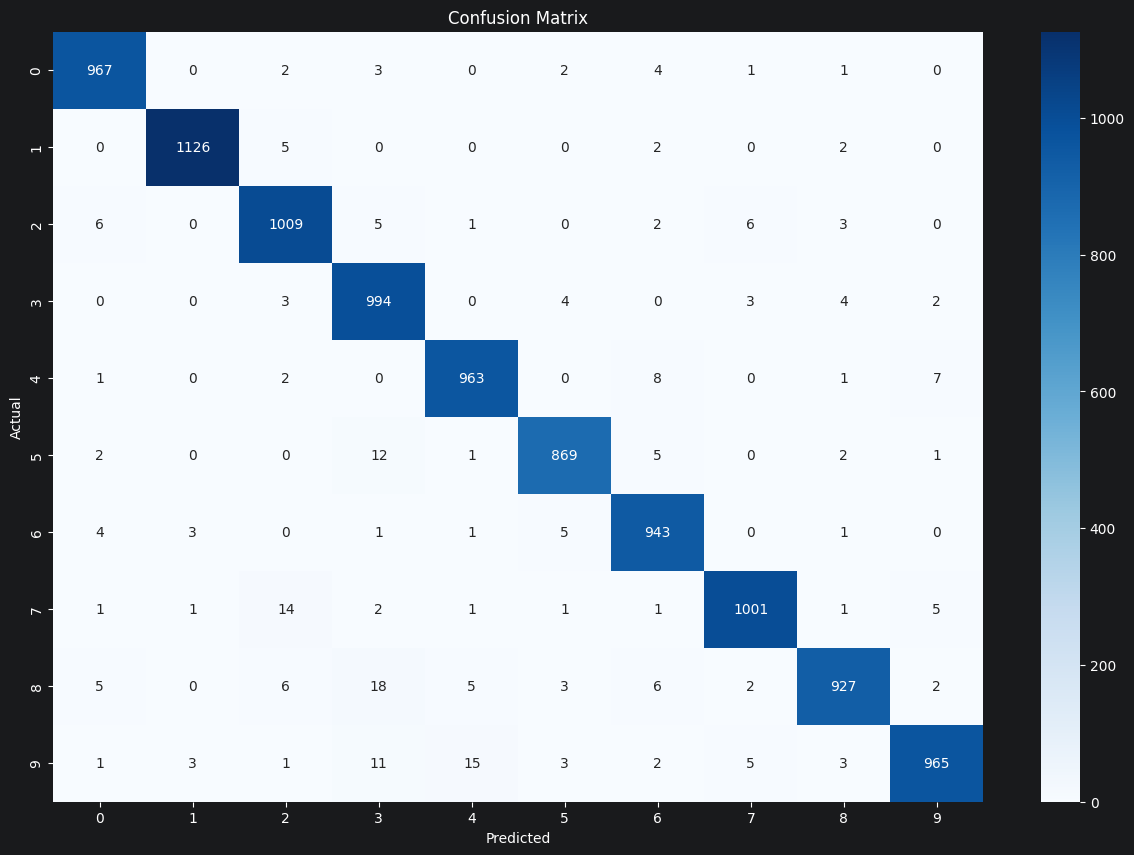

In [127]:
# Creates a confusion matrix rows = actual values, cols = predicted values
# cm[row][col] = number of times column number was predicted when in actuality it was row number
cm = confusion_matrix(np.argmax(y_test, axis=1), np.argmax(y_pred, axis=1))

# creates a figure of size 15 by 10, only have 1 plot
fig, ax = plt.subplots(figsize=(15, 10))

# draws a heatmap onto that plot, with annotations, a blue color theme, and every number as ints
ax = sns.heatmap(cm, annot=True, cmap='Blues', fmt='d', ax=ax)

# labels the heatmap
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Confusion Matrix")